# Clustering Analysis
**Part A:** K-Means on the Iris dataset (elbow method)  |  **Part B:** K-Medoids on the credit card dataset (silhouette method)

Both datasets are downloaded from Kaggle using `kagglehub`.

In [1]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.


## Part A: K-Means Clustering on Iris

In [2]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.style.use("seaborn-v0_8-whitegrid")

def load_csv(handle):
    return pd.read_csv(glob.glob(os.path.join(kagglehub.dataset_download(handle), "*.csv"))[0])

iris = load_csv("uciml/iris")
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = iris[features].values            # all four features are in cm, so no scaling is needed
print(iris.shape, "| missing values:", iris.isnull().sum().sum())
iris.head()

(150, 6) | missing values: 0


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**Elbow method:** plot the within-cluster sum of squares (inertia) for K = 1 to 10; the "elbow" is where the curve stops dropping sharply.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

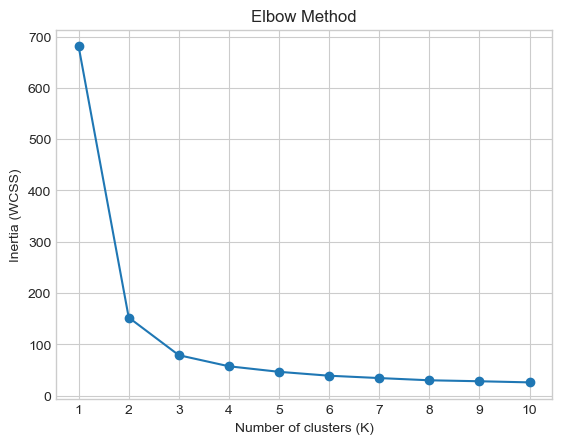

In [3]:
ks = range(1, 11)
inertia = [KMeans(k, n_init=10, random_state=42).fit(X).inertia_ for k in ks]

plt.plot(ks, inertia, marker="o")
plt.title("Elbow Method"); plt.xlabel("Number of clusters (K)"); plt.ylabel("Inertia (WCSS)")
plt.xticks(ks)
plt.show()

**Fit K-Means with the chosen K** (the elbow is at K = 3) and compare the clusters with the actual species.

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


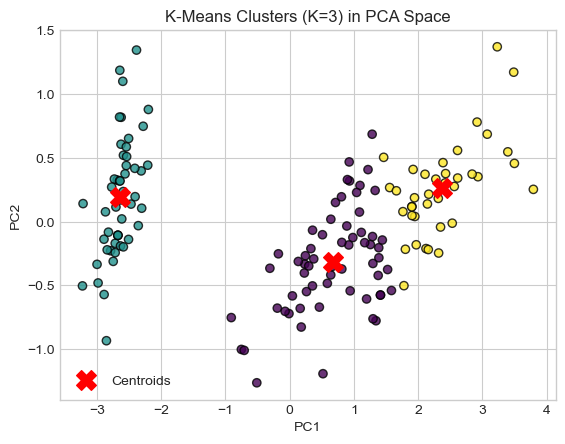

Silhouette score: 0.553



Cluster,0,1,2
Species,,,
Iris-setosa,0,50,0
Iris-versicolor,48,0,2
Iris-virginica,14,0,36


In [4]:
K = 3
km = KMeans(K, n_init=10, random_state=42).fit(X)
iris["Cluster"] = km.labels_

pca = PCA(n_components=2).fit(X)
X_pca, centers = pca.transform(X), pca.transform(km.cluster_centers_)

plt.scatter(*X_pca.T, c=km.labels_, cmap="viridis", edgecolor="k", alpha=0.8)
plt.scatter(*centers.T, c="red", marker="X", s=200, label="Centroids")
plt.title(f"K-Means Clusters (K={K}) in PCA Space"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
plt.show()

print(f"Silhouette score: {silhouette_score(X, km.labels_):.3f}\n")
pd.crosstab(iris["Species"], iris["Cluster"])

**Conclusion:** the elbow appears at about K = 3, matching the three Iris species. Setosa forms its own cluster, while versicolor and virginica overlap slightly.

## Part B: K-Medoids Clustering on the Credit Card Dataset
K-Medoids uses actual data points as cluster centres, which makes it less sensitive to outliers than K-Means. It needs the full pairwise distance matrix, so a random sample of 2,000 customers is used to keep it fast.

In [5]:
cc = load_csv("arjunbhasin2013/ccdata")
cc = cc.drop(columns="CUST_ID")
cc = cc.fillna(cc.median())                       # MINIMUM_PAYMENTS and CREDIT_LIMIT have a few missing values
cc = cc.sample(2000, random_state=42).reset_index(drop=True)

Xc = StandardScaler().fit_transform(cc)
D = np.linalg.norm(Xc[:, None] - Xc[None], axis=2)   # pairwise Euclidean distance matrix
print(cc.shape)
cc.head()

(2000, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,16.834929,0.454545,15.00,15.00,0.00,209.025389,0.090909,0.090909,0.000000,0.090909,1,1,7500.0,430.213001,86.959785,0.000000,11
1,540.020858,1.000000,612.23,495.61,116.62,1708.923217,0.666667,0.166667,0.500000,0.333333,10,10,2000.0,1642.068707,419.956251,0.000000,12
2,119.237712,1.000000,342.74,0.00,342.74,0.000000,1.000000,0.000000,1.000000,0.000000,0,20,2000.0,327.166041,165.207233,0.000000,12
3,894.081947,1.000000,1901.71,1853.11,48.60,206.618780,0.666667,0.666667,0.416667,0.083333,1,33,1500.0,947.130141,220.745296,0.000000,12
4,1294.145453,1.000000,3059.10,1836.98,1222.12,0.000000,1.000000,0.416667,1.000000,0.000000,0,42,7000.0,5560.033502,497.637767,0.083333,12


**K-Medoids implementation** (alternating assignment and medoid update, best of 5 random starts).

In [6]:
def kmedoids(D, k, n_init=5, max_iter=100, seed=0):
    rng, best = np.random.default_rng(seed), None
    for _ in range(n_init):
        medoids = rng.choice(len(D), k, replace=False)
        for _ in range(max_iter):
            labels = D[:, medoids].argmin(axis=1)
            new = medoids.copy()
            for j in range(k):                       # new medoid = point with the smallest total distance to its cluster
                idx = np.where(labels == j)[0]
                if len(idx):
                    new[j] = idx[D[np.ix_(idx, idx)].sum(axis=1).argmin()]
            if np.array_equal(new, medoids):
                break
            medoids = new
        cost = D[np.arange(len(D)), medoids[labels]].sum()
        if best is None or cost < best[0]:
            best = (cost, medoids, labels)
    return best[1], best[2]

**Silhouette method:** compute the average silhouette score for K = 2 to 10; the best K has the highest score.

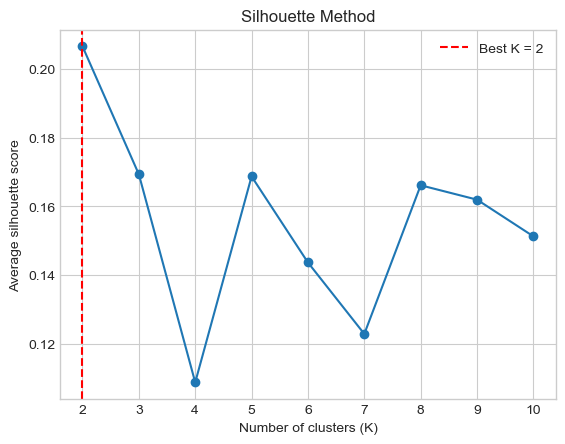

Best K = 2 (silhouette = 0.207)


In [7]:
ks = range(2, 11)
scores = {}
for k in ks:
    _, labels = kmedoids(D, k)
    scores[k] = silhouette_score(D, labels, metric="precomputed")

best_k = max(scores, key=scores.get)
plt.plot(list(scores), list(scores.values()), marker="o")
plt.axvline(best_k, color="red", ls="--", label=f"Best K = {best_k}")
plt.title("Silhouette Method"); plt.xlabel("Number of clusters (K)"); plt.ylabel("Average silhouette score"); plt.legend()
plt.show()
print(f"Best K = {best_k} (silhouette = {scores[best_k]:.3f})")

**Final clustering and cluster profiles.**

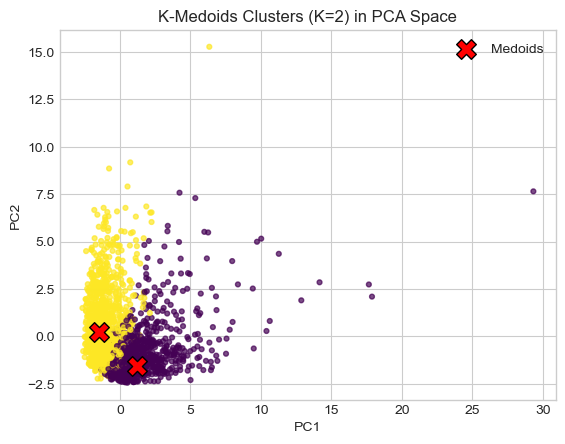

Customers per cluster:
 Cluster
0     837
1    1163 



,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
Cluster,,,,,
0,1209.0,2028.0,369.0,4681.0,2156.0
1,1738.0,301.0,1351.0,4049.0,1398.0


In [8]:
medoids, labels = kmedoids(D, best_k)
cc["Cluster"] = labels

pca = PCA(n_components=2).fit(Xc)
Z = pca.transform(Xc)
plt.scatter(*Z.T, c=labels, cmap="viridis", s=12, alpha=0.7)
plt.scatter(*Z[medoids].T, c="red", marker="X", s=200, edgecolor="k", label="Medoids")
plt.title(f"K-Medoids Clusters (K={best_k}) in PCA Space"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend()
plt.show()

print("Customers per cluster:\n", cc["Cluster"].value_counts().sort_index().to_string(), "\n")
cc.groupby("Cluster")[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]].mean().round(0)

**Conclusion:** the silhouette method selects the number of customer segments, and the cluster profiles show how the groups differ, for example high-spending customers versus customers who mainly use cash advances.